In [1]:
# Importations
import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import time
import numpy as np
import statistics
import matplotlib.pyplot as plt
import seaborn as sns

# Vérification du GPU et de la version de PyTorch (Doit être >= 2.0 pour torch.compile)
print(f"Version de PyTorch : {torch.__version__}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Appareil utilisé : {device}")

if device.type != 'cuda':
    print("ATTENTION : Veuillez activer l'accélérateur GPU (T4) dans Exécution > Modifier le type d'exécution.")

Version de PyTorch : 2.14.1+cu130
Appareil utilisé : cuda


In [2]:
# Prétraitement standard ImageNet pour ResNet-18
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Chargement du jeu de test CIFAR-10
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

# Sélection stricte des 50 mêmes images
SUBSET_SIZE = 50
subset_indices = list(range(SUBSET_SIZE))
test_subset = torch.utils.data.Subset(testset, subset_indices)
testloader = torch.utils.data.DataLoader(test_subset, batch_size=1, shuffle=False)

print(f"Nombre d'images pour le test : {len(testloader)}")

100%|██████████| 170M/170M [12:51<00:00, 221kB/s]


Nombre d'images pour le test : 50


In [3]:
# 1. Haut niveau : Chargement du modèle PyTorch
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)
model.eval()
model.to(device)

# 2. Format / Middle Level : Compilation native du modèle avec torch.compile
# Le backend 'inductor' fusionne les opérateurs et génère du code Triton pour CUDA
print("Compilation du modèle avec torch.compile...")
compiled_model = torch.compile(model, mode="reduce-overhead")
print("Compilation terminée !")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 123MB/s]


Compilation du modèle avec torch.compile...
Compilation terminée !


In [4]:
def evaluate_pytorch_pipeline(model, dataloader, num_runs=3):
    # Warm-up (Chauffe : la première exécution déclenche la vraie compilation JIT de PyTorch)
    print("Phase de chauffe (Warm-up - la première image sera lente)...")
    with torch.no_grad():
        for _ in range(5):
            dummy = torch.randn(1, 3, 224, 224, device=device)
            _ = model(dummy)
            torch.cuda.synchronize()

    latencies = []
    throughputs = []

    for run in range(num_runs):
        run_latencies = []
        correct_top1 = 0
        total = 0

        with torch.no_grad(): # Désactive le calcul des gradients (important pour l'inférence)
            for images, labels in dataloader:
                images = images.to(device)
                labels = labels.to(device)

                # Mesure précise du temps sur GPU
                torch.cuda.synchronize()
                start_time = time.perf_counter()

                outputs = model(images)

                torch.cuda.synchronize() # On attend que le GPU ait fini pour arrêter le chrono
                end_time = time.perf_counter()

                inference_time = end_time - start_time
                run_latencies.append(inference_time)

                # Précision
                predicted_class = torch.argmax(outputs, dim=1)
                if predicted_class.item() == labels.item():
                    correct_top1 += 1
                total += 1

        # Métriques pour l'itération
        total_time = sum(run_latencies)
        avg_latency = (total_time / total) * 1000 # en ms
        throughput = total / total_time # en img/s
        accuracy = (correct_top1 / total) * 100

        latencies.append(avg_latency)
        throughputs.append(throughput)

        print(f"Run {run+1}/3 - Latence moy: {avg_latency:.2f} ms | Débit: {throughput:.2f} img/s | Acc: {accuracy:.2f}%")

    return latencies, throughputs, accuracy

# Lancement de l'évaluation
latencies_pt, throughputs_pt, acc_pt = evaluate_pytorch_pipeline(compiled_model, testloader, num_runs=3)

Phase de chauffe (Warm-up - la première image sera lente)...


W1106 21:34:27.493000 1194 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


Run 1/3 - Latence moy: 4.74 ms | Débit: 210.88 img/s | Acc: 0.00%
Run 2/3 - Latence moy: 2.98 ms | Débit: 335.80 img/s | Acc: 0.00%
Run 3/3 - Latence moy: 2.55 ms | Débit: 392.57 img/s | Acc: 0.00%


--- Statistiques Latence (ms) ---
Moyenne    : 3.42
Écart-type : 1.16
Minimum    : 2.55
Maximum    : 4.74

--- Statistiques Débit (images/s) ---
Moyenne    : 313.09
Écart-type : 92.95
Minimum    : 210.88
Maximum    : 392.57



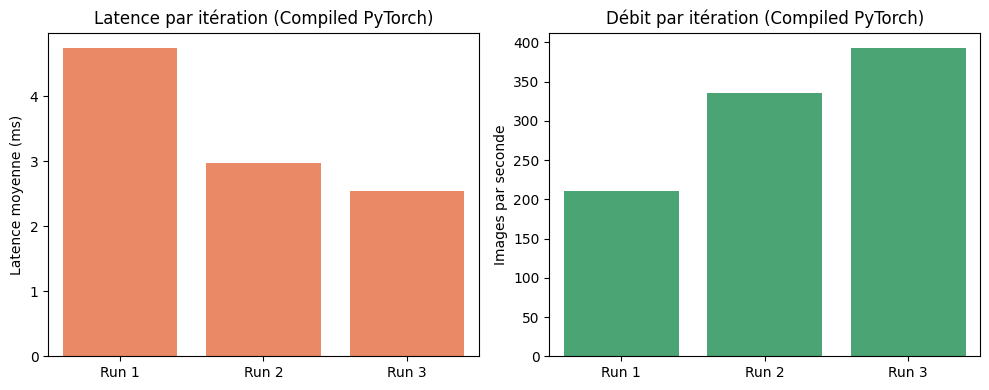

In [5]:
# Calcul des statistiques
def print_stats(name, data):
    print(f"--- Statistiques {name} ---")
    print(f"Moyenne    : {statistics.mean(data):.2f}")
    print(f"Écart-type : {statistics.stdev(data):.2f}")
    print(f"Minimum    : {min(data):.2f}")
    print(f"Maximum    : {max(data):.2f}\n")

print_stats("Latence (ms)", latencies_pt)
print_stats("Débit (images/s)", throughputs_pt)

# Visualisation intra-pipeline
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.barplot(x=[f"Run {i+1}" for i in range(3)], y=latencies_pt, color="coral")
plt.title("Latence par itération (Compiled PyTorch)")
plt.ylabel("Latence moyenne (ms)")

plt.subplot(1, 2, 2)
sns.barplot(x=[f"Run {i+1}" for i in range(3)], y=throughputs_pt, color="mediumseagreen")
plt.title("Débit par itération (Compiled PyTorch)")
plt.ylabel("Images par seconde")

plt.tight_layout()
plt.show()

# Résultats pour le rapport final
pt_compile_results = {
    'latency_mean': statistics.mean(latencies_pt),
    'latency_std': statistics.stdev(latencies_pt),
    'throughput_mean': statistics.mean(throughputs_pt),
    'throughput_std': statistics.stdev(throughputs_pt),
    'accuracy': acc_pt
}